# **Flight Delay Prediction**

Проект по машинному обучению для прогнозирования задержки вылета пассажирского рейса на 15 и более минут.

Датасет: [US Flight Delays, Bureau of Transportation Statistics (BTS)](https://www.kaggle.com/datasets/usdot/flight-delays/data), опубликованный на [Kaggle](https://www.kaggle.com/).

Целевая переменная:
**TARGET = 1**, если задержка вылета **превышает 15 минут или равна**, иначе **0**.

В проекте был проведён разведочный анализ данных, исследованы распределения признаков, выбросы, пропуски, категориальные признаки и корреляции между числовыми переменными.

Для предотвращения утечки данных из модели были исключены признаки, которые становятся известны только после вылета или завершения рейса.

Был сформирован временной train/test split:
* **Train** — январь–сентябрь;
* **Test** — ноябрь–декабрь.

Категориальные признаки обрабатывались с помощью **One-Hot Encoding**, числовые признаки масштабировались.

Для проверки устойчивости результатов использовалась временная кросс-валидация **TimeSeriesSplit**.



Для моделей LightGBM и CatBoost был выполнен подбор гиперпараметров с использованием [Optuna](https://optuna.org/).

Для оценки качества использовались:
* **ROC-AUC**
* **PR-AUC**
* **Precision**
* **Recall**
* **F1-score**
* **F2-score**
* **Accuracy**.

# Import libraries and modules
Импортируем необходимые библиотеки модули:

In [86]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch.nn as nn

import optuna
import time
import warnings
import torch

from sklearn.model_selection import TimeSeriesSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import (
        accuracy_score, average_precision_score, f1_score, fbeta_score, 
        precision_score, recall_score, roc_auc_score
)
from sklearn.exceptions import ConvergenceWarning
from sklearn.base import clone

from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from IPython.display import display, HTML
from torch.utils.data import DataLoader, TensorDataset

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


# Initial dataset analysis
Проведём первоначальный анализ датасета:

In [87]:
plt.style.use('seaborn-v0_8-whitegrid')
df = pd.read_csv('/kaggle/input/datasets/usdot/flight-delays/flights.csv', low_memory=False)
print(f'Shape of dataset is {df.shape[0]} by {df.shape[1]}')

Shape of dataset is 5819079 by 31


In [88]:
pd.set_option('display.max_columns', None)
df.head(7)

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,DEPARTURE_TIME,DEPARTURE_DELAY,TAXI_OUT,WHEELS_OFF,SCHEDULED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,WHEELS_ON,TAXI_IN,SCHEDULED_ARRIVAL,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,2354.0,-11.0,21.0,15.0,205.0,194.0,169.0,1448,404.0,4.0,430,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,2.0,-8.0,12.0,14.0,280.0,279.0,263.0,2330,737.0,4.0,750,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,18.0,-2.0,16.0,34.0,286.0,293.0,266.0,2296,800.0,11.0,806,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,15.0,-5.0,15.0,30.0,285.0,281.0,258.0,2342,748.0,8.0,805,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,24.0,-1.0,11.0,35.0,235.0,215.0,199.0,1448,254.0,5.0,320,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
5,2015,1,1,4,DL,806,N3730B,SFO,MSP,25,20.0,-5.0,18.0,38.0,217.0,230.0,206.0,1589,604.0,6.0,602,610.0,8.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
6,2015,1,1,4,NK,612,N635NK,LAS,MSP,25,19.0,-6.0,11.0,30.0,181.0,170.0,154.0,1299,504.0,5.0,526,509.0,-17.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [89]:
df_info = df.dtypes.reset_index()
df_info.columns = ['Feature', 'Type']
df_info['Gaps'] = df.isna().sum().values
df_info['Fill percent (%)'] = ((1 - df_info['Gaps'] / df.shape[0]) * 100)

display(df_info.style.format({'Fill percent (%)': '{:.2f}'}).hide())

Feature,Type,Gaps,Fill percent (%)
YEAR,int64,0,100.00
MONTH,int64,0,100.00
DAY,int64,0,100.00
DAY_OF_WEEK,int64,0,100.00
AIRLINE,object,0,100.00
FLIGHT_NUMBER,int64,0,100.00
TAIL_NUMBER,object,14721,99.75
ORIGIN_AIRPORT,object,0,100.00
DESTINATION_AIRPORT,object,0,100.00
SCHEDULED_DEPARTURE,int64,0,100.00


## Filtering dataset sizes
Перенаправленные рейсы исключены из анализа, поскольку мы ограничиваем задачу стандартными рейсами без изменения маршрута.  Будем рассматривать топ 15 аэропортов, чтобы ускорить обучение на выборке поменьше.

Также уберём строки, в которых `DEPARTURE_DELAY` неопределён, так как признак будет участвовать в создании таргета.

In [90]:
df = df[(df['CANCELLED'] == 0) & (df['DIVERTED'] == 0)].copy()
df.dropna(subset=['DEPARTURE_DELAY'], inplace=True)

top_15_airports = df['ORIGIN_AIRPORT'].value_counts().nlargest(15).index.tolist()

df = df[
    (df['ORIGIN_AIRPORT'].isin(top_15_airports)) &
    (df['DESTINATION_AIRPORT'].isin(top_15_airports))
].copy()

Снова посмотрим на количество строк и пропусков.

In [91]:
print(f'Shape of clean dataset is {df.shape[0]} by {df.shape[1]}')
df_isna = df.isna().sum().reset_index()
df_isna.columns = ['Feature', 'Gaps']
df_isna['Fill percent (%)'] = ((1 - df_isna['Gaps'] / df.shape[0]) * 100)
display(df_isna.style.format({'Fill percent (%)': '{:.2f}'}).hide())

Shape of clean dataset is 833566 by 31


Feature,Gaps,Fill percent (%)
YEAR,0,100.00
MONTH,0,100.00
DAY,0,100.00
DAY_OF_WEEK,0,100.00
AIRLINE,0,100.00
FLIGHT_NUMBER,0,100.00
TAIL_NUMBER,0,100.00
ORIGIN_AIRPORT,0,100.00
DESTINATION_AIRPORT,0,100.00
SCHEDULED_DEPARTURE,0,100.00


## Features filtering

Что сразу бросается в глаза:
* `CANCELLATION_REASON`
* `AIR_SYSTEM_DELAY`
* `SECURITY_DELAY`
* `AIRLINE_DELAY`
* `LATE_AIRCRAFT_DELAY`
* `WEATHER_DELAY`

Эти колонки заполняются только в том случае, если **уже** произошла задержка прилёта. То есть, возьмём в пример, что самолёт вылетел с задержкой в 20 минут, нагнал время и прилетел уже с задержкой в 10 минут. Тогда по инструкции эти колонки должны быть пустыми, ведь задержка прилёта составляет не более 15 минут, хотя задержка вылета всё же была. Задачу это решить не поможет, так что можем удалить эти признаки.

`CANCELLATION_REASON` имеет Fill percent (%) = 0, мы же отфильтровали рейсы, которые отменены или перенаправлены. Признак бесполезный, как и `DIVERTED` и `CANCELLED`, ведь они содержат только нули по предварительному фильтру.


Также мы ***прогнозируем***, будет ли рейс задержан, значит все данные, которые заполняются в моменте отъезда от здания аэропорта или трапа, маневрирования по ВПП, время полёта и фактические времена вылета и прибытия, нами не рассматриваются. Мы знать о них не может ДО вылета текущего рейса. Удаляем:

* `DEPARTURE_TIME` - фактическое время вылета. Можем сразу посчитать задержку с `SCHEDULED_DEPARTURE`
* `DEPARTURE_DELAY` - таргет
* `TAXI_OUT` - время маневрирования до вылета
* `WHEELS_OFF` - время, когда самолёт был полностью в воздухе
* `ELAPSED_TIME` - фактическое время с учётом маневрирования
* `AIR_TIME` - время нахождения в воздухе
* `WHEELS_ON` - время, когда самолёт коснулся ВВП
* `TAXI_IN` - время маневрирования до остановки
* `ARRIVAL_TIME` - время фактического прилёта в назначенный аэропорт
* `ARRIVAL_DELAY` - время задержки прибытия
* `FLIGHT_NUMBER` - коммерческий номер (id) у рейса
* `YEAR` - год в датасете всего один

In [92]:
df['TARGET'] = (df['DEPARTURE_DELAY'] >= 15).astype(int)

df = df.drop(columns=[
    'CANCELLATION_REASON',
    'AIR_SYSTEM_DELAY',
    'SECURITY_DELAY',
    'AIRLINE_DELAY',
    'LATE_AIRCRAFT_DELAY',
    'WEATHER_DELAY',

    'DEPARTURE_TIME',
    'DEPARTURE_DELAY',
    'TAXI_OUT',
    'WHEELS_OFF',
    'ELAPSED_TIME',
    'AIR_TIME',
    'WHEELS_ON',
    'TAXI_IN',
    'ARRIVAL_TIME',
    'ARRIVAL_DELAY',
    'CANCELLATION_REASON',
    'DIVERTED',
    'CANCELLED',
    'FLIGHT_NUMBER',
    'YEAR'
], axis=1)

Снова посмотрим на признаки и количество уникальных значений:

In [93]:
display(df.head(7))

df_info = df.dtypes.reset_index()
df_info.columns = ['Feature', 'Type']
df_info['Unique count'] = df.nunique().values

display(df_info.style.hide())

,MONTH,DAY,DAY_OF_WEEK,AIRLINE,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,SCHEDULED_TIME,DISTANCE,SCHEDULED_ARRIVAL,TARGET
2,1,1,4,US,N171US,SFO,CLT,20,286.0,2296,806,0
5,1,1,4,DL,N3730B,SFO,MSP,25,217.0,1589,602,0
6,1,1,4,NK,N635NK,LAS,MSP,25,181.0,1299,526,0
7,1,1,4,US,N584UW,LAX,CLT,30,273.0,2125,803,0
8,1,1,4,AA,N3LAAA,SFO,DFW,30,195.0,1464,545,0
9,1,1,4,DL,N826DN,LAS,ATL,30,221.0,1747,711,0
10,1,1,4,DL,N958DN,DEN,ATL,30,173.0,1199,523,0


Feature,Type,Unique count
MONTH,int64,11
DAY,int64,31
DAY_OF_WEEK,int64,7
AIRLINE,object,13
TAIL_NUMBER,object,4438
ORIGIN_AIRPORT,object,15
DESTINATION_AIRPORT,object,15
SCHEDULED_DEPARTURE,int64,1224
SCHEDULED_TIME,float64,363
DISTANCE,int64,103


In [94]:
months = df['MONTH'].unique()
for i in range(len(months)):
    if i + 1 != months[i]:
        print('Missing month number is', i + 1)
        break

Missing month number is 10


Не хватает одного месяца, наш очищенный датасет не содержит полётов за октябрь.

Будем использовать валидацию с помощью "расширяющегося окна"/"скользящего окна". Мы будем разбивать данные на временные промежутки, при этом обучать на одном, проводить валидацию на другом, постепенно увеличивая тренировочные данные с каждым проходом по фолдам.

In [95]:
df_train = df[df['MONTH'] <= 9]
df_test = df[df['MONTH'] >= 11]

df_train = df_train.sort_values(
    by=['MONTH', 'DAY', 'SCHEDULED_DEPARTURE']
).reset_index(drop=True)

df_test = df_test.sort_values(
    by=['MONTH', 'DAY', 'SCHEDULED_DEPARTURE']
).reset_index(drop=True)

print(f'Shape train is {df_train.shape[0]} by {df_train.shape[1]}')
print(f'Shape test is {df_test.shape[0]} by {df_test.shape[1]}')

Shape train is 681978 by 12
Shape test is 151588 by 12


# Exploratory data analysis (EDA)
Теперь проведём полноценный анализ данных на тренировочном датасете. Оценим дисбаланс классов:

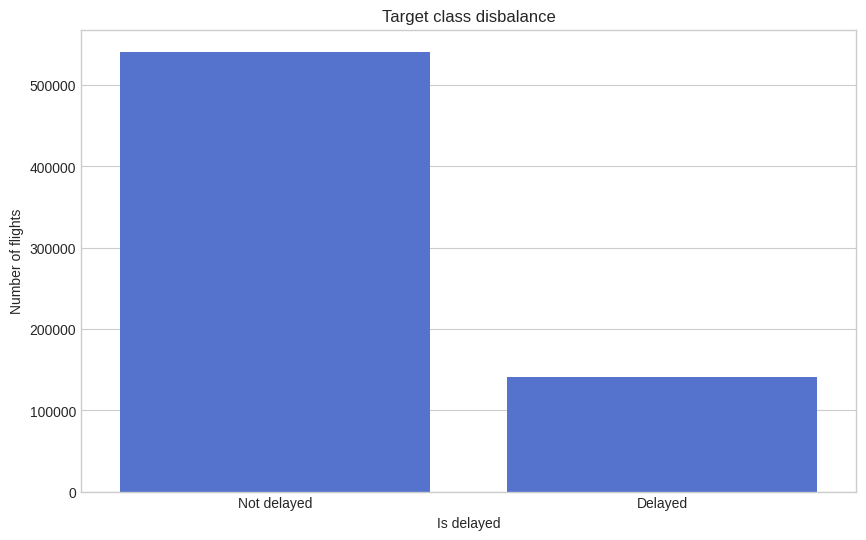

In [96]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df_train, x=df_train['TARGET'], color='royalblue')
plt.title('Target class disbalance')
plt.xlabel('Is delayed')
plt.xticks(ticks=[0, 1], labels=['Not delayed', 'Delayed'])
plt.ylabel('Number of flights')
plt.show()

## Countplots by time-related features
Посмотрим на количество полётов по временным признакам:

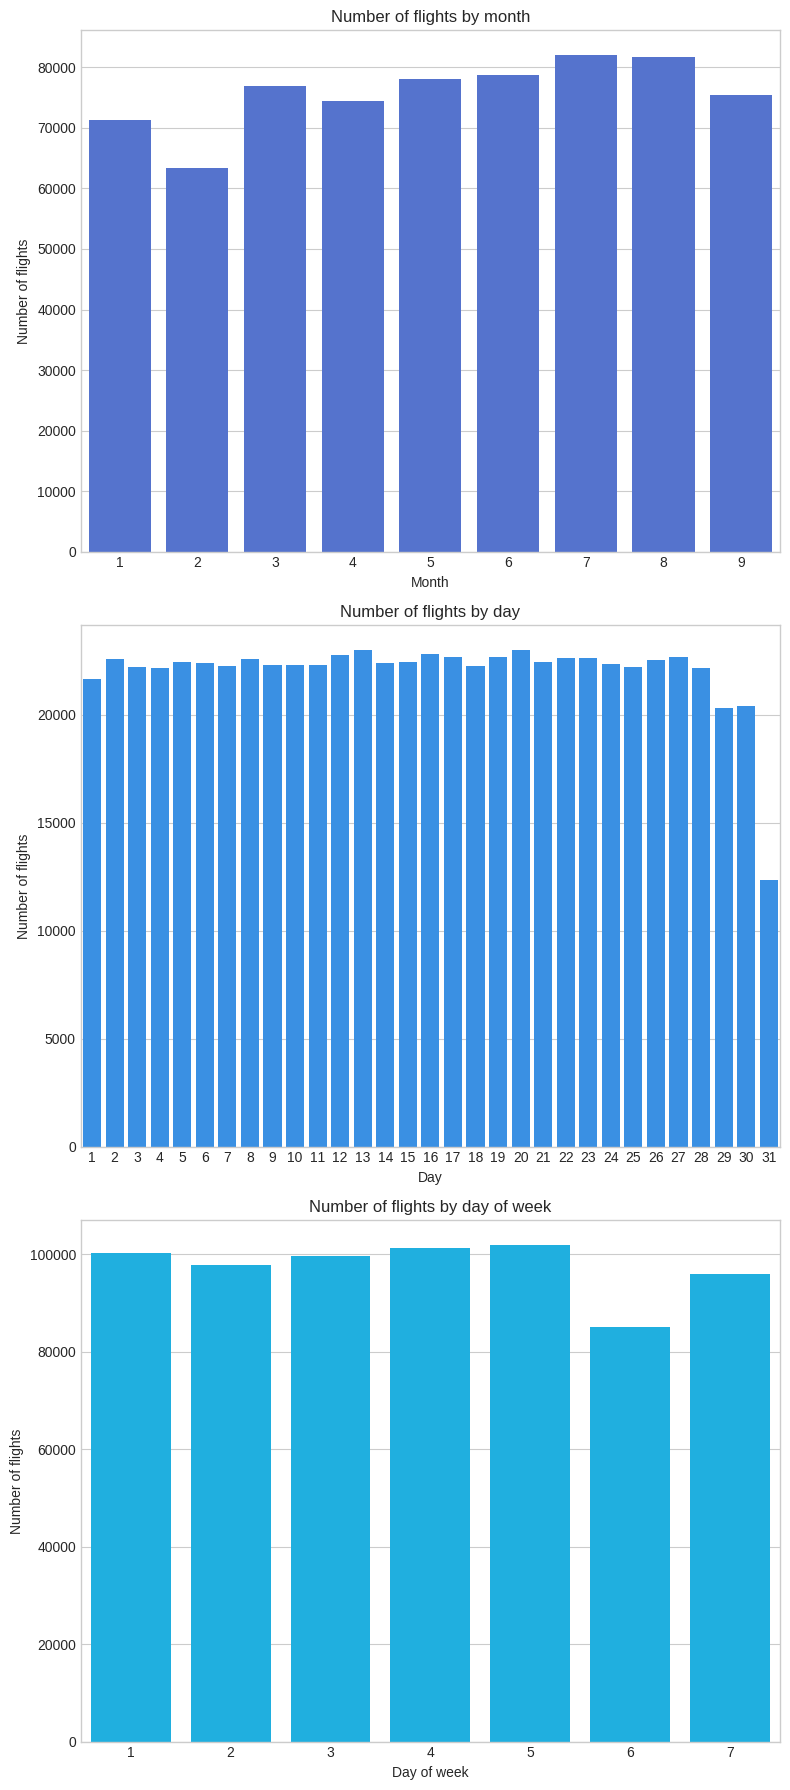

In [97]:
col_arr = ['royalblue', 'dodgerblue', 'deepskyblue']

fig, ax = plt.subplots(3, 1, figsize=(8, 18))
for i, item in enumerate(['MONTH', 'DAY', 'DAY_OF_WEEK']):
    sns.countplot(data=df_train, x=item, color=col_arr[i], ax=ax[i])
    ax[i].set_title(f'Number of flights by {item.lower().replace('_', ' ')}')
    ax[i].set_xlabel(item.capitalize().replace('_', ' '))
    ax[i].set_ylabel('Number of flights')

plt.tight_layout()
plt.show()

## Barplots by airports
Оценим самые нагруженные по количеству полётов аэропорты:

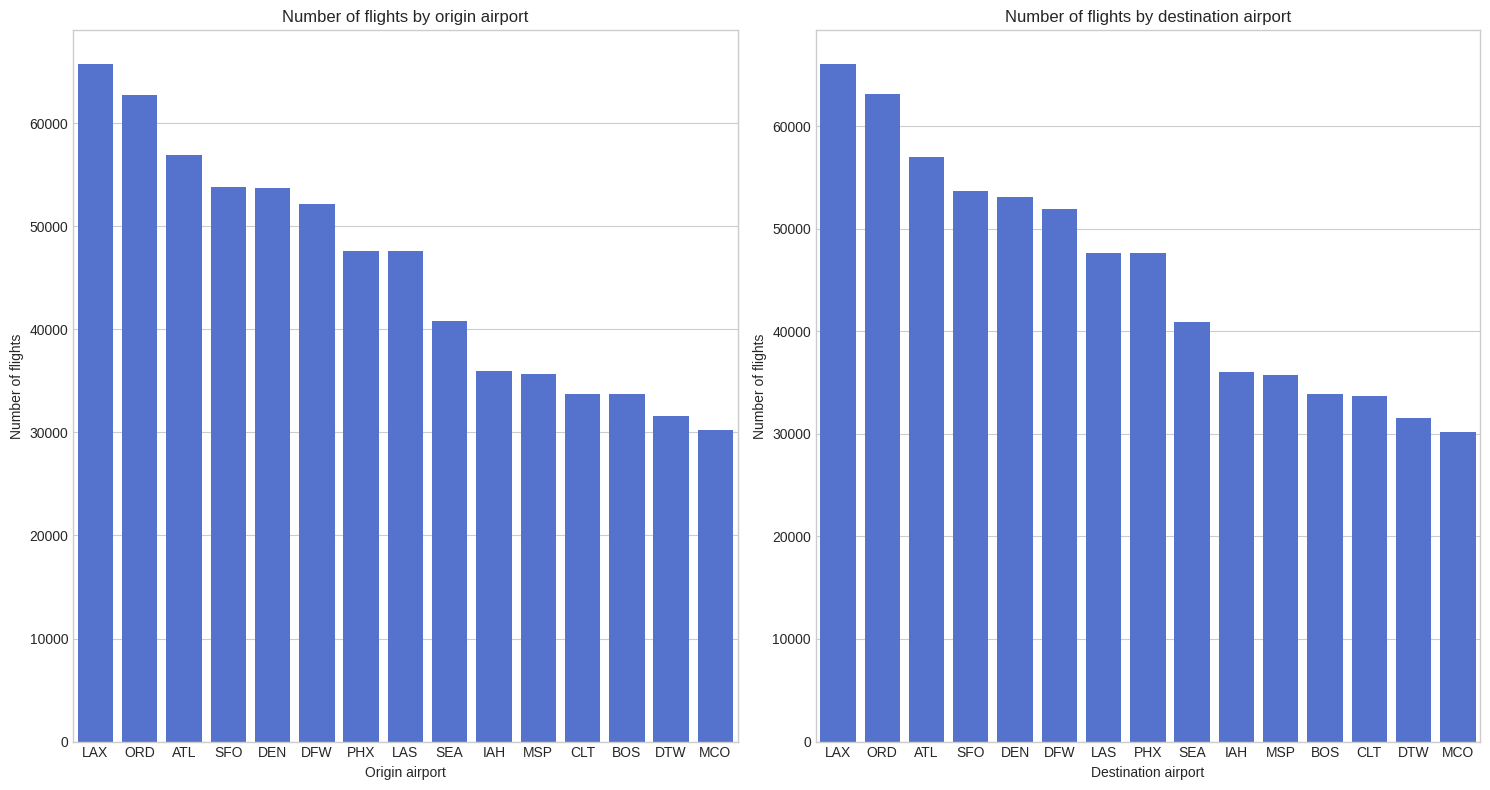

In [98]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8))
axes = axes.flatten()
for i, item in enumerate(['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT']):
    counts = df_train[item].value_counts()
    sns.barplot(x=counts.index, y=counts.values, color='royalblue', ax=axes[i])
    axes[i].set_title(f'Number of flights by {item.lower().replace('_', ' ')}')
    axes[i].set_xlabel(item.capitalize().replace('_', ' '))
    axes[i].set_ylabel('Number of flights')

plt.tight_layout()
plt.show()

## Outlier values by numeric features
Теперь оценим выбросы на дистанции и времени полёта.

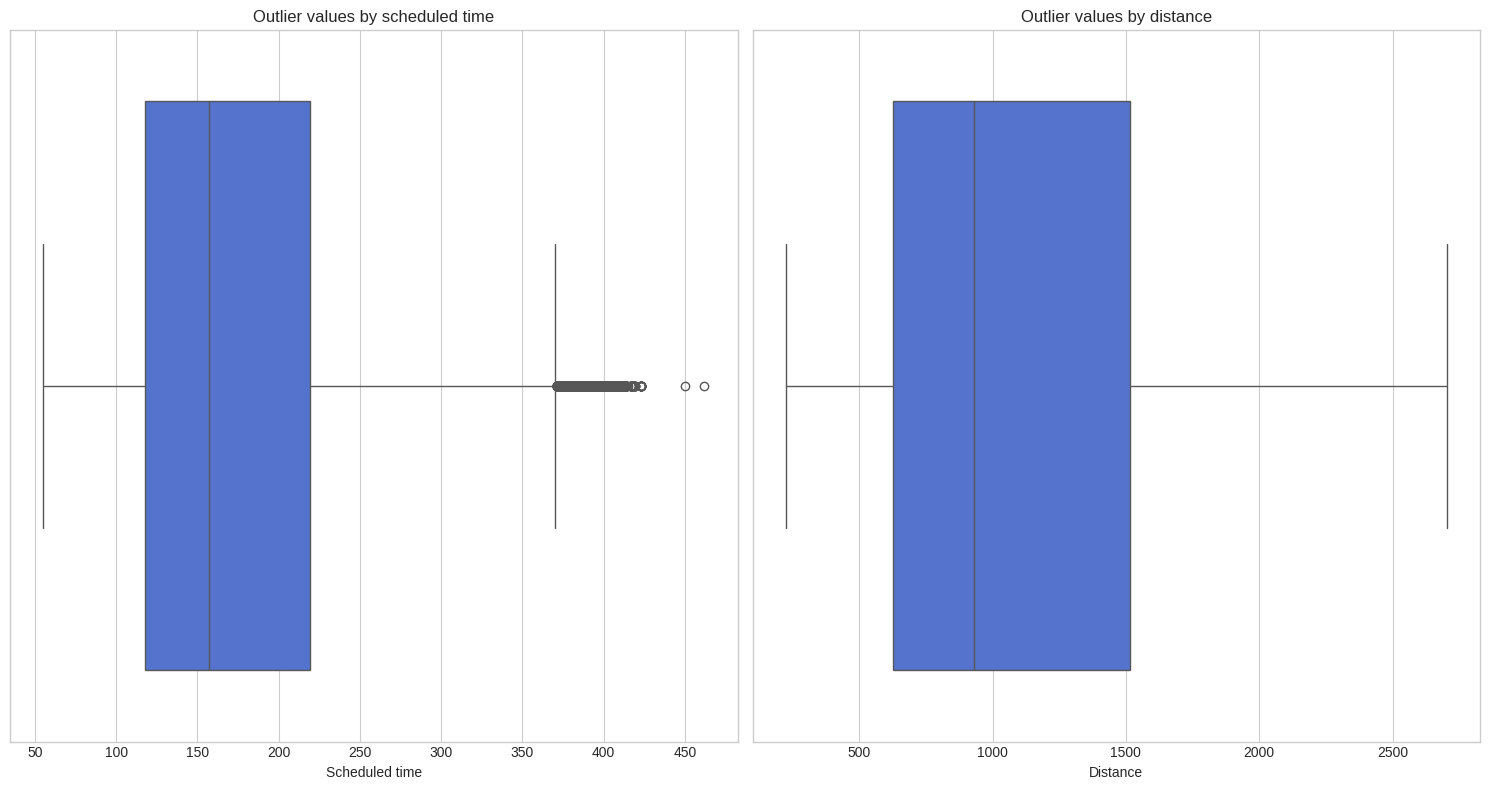

In [99]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8))
axes = axes.flatten()
for i, item in enumerate(['SCHEDULED_TIME', 'DISTANCE']):
    sns.boxplot(data=df_train, x=item, color='royalblue', ax=axes[i])
    axes[i].set_title(f'Outlier values by {item.lower().replace('_', ' ')}')
    axes[i].set_xlabel(item.capitalize().replace('_', ' '))

plt.tight_layout()
plt.show()

## Probability of delays
Оценим вероятности задержек по авиакомпаниям, аэропортам отправления, часам, календарным дням и дням недели:

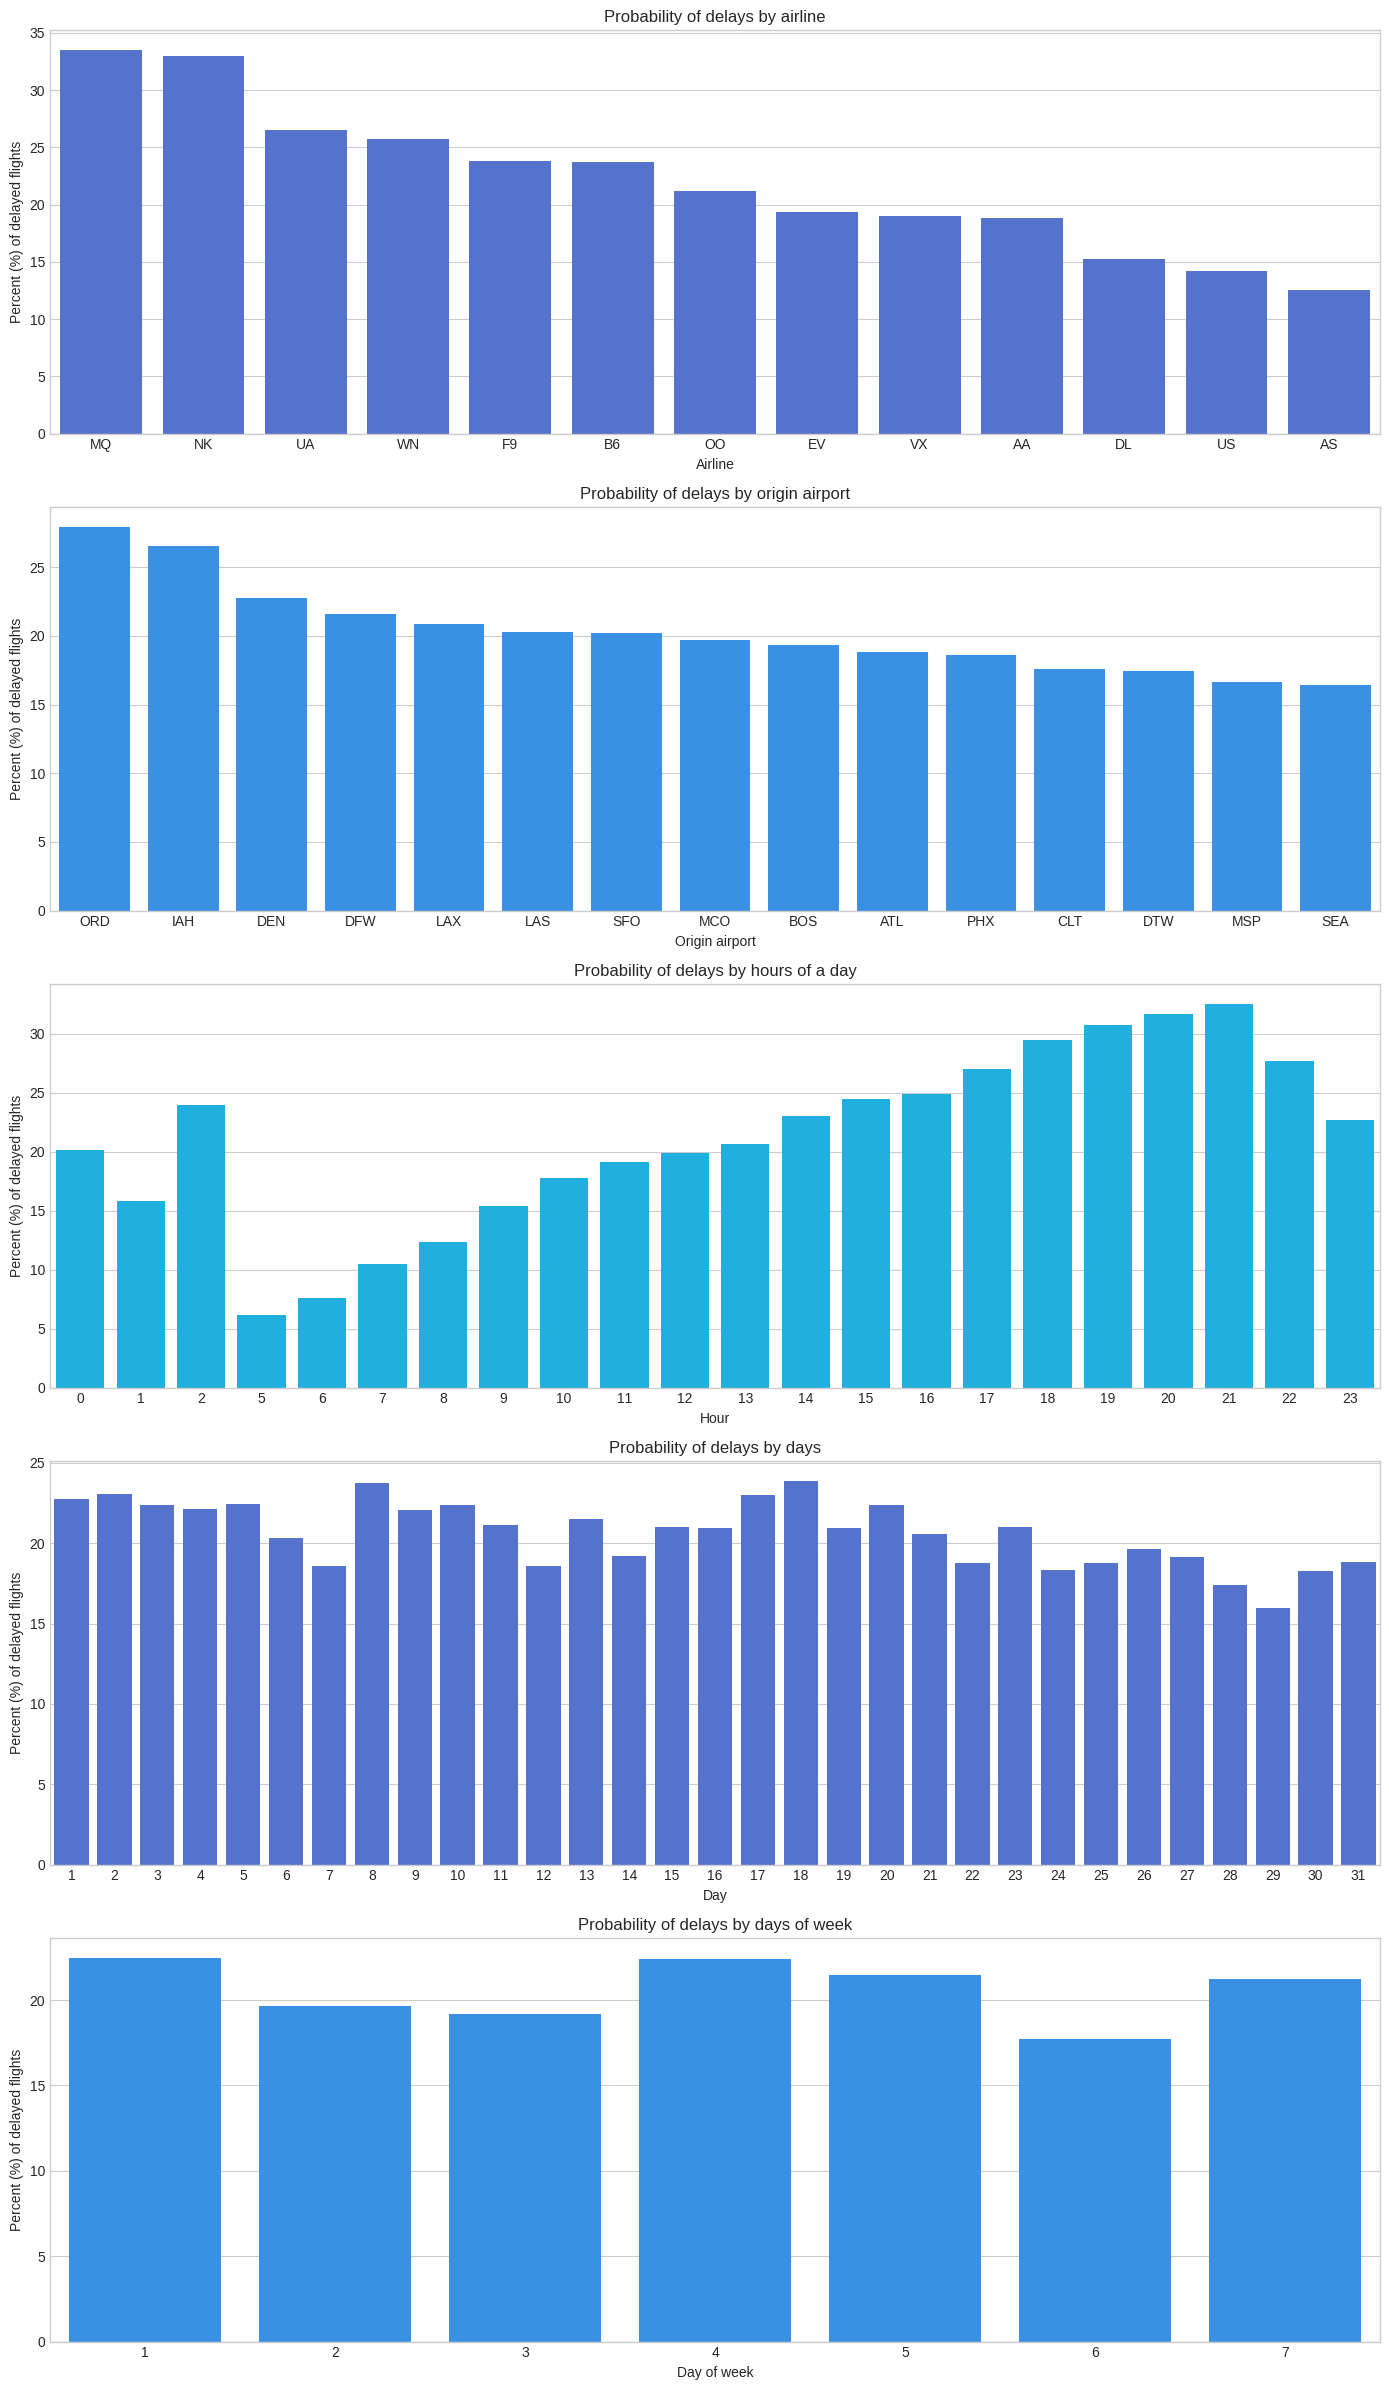

In [100]:
baseline_delay_rate = df_train['TARGET'].mean() * 100

fig, ax = plt.subplots(5, 1, figsize=(14, 24))

airline_delay = df_train.groupby('AIRLINE')['TARGET'].mean().sort_values(ascending=False) * 100

sns.barplot(x=airline_delay.index, y=airline_delay, ax=ax[0], color=col_arr[0])
ax[0].set_title('Probability of delays by airline')
ax[0].set_xlabel('Airline')
ax[0].set_ylabel('Percent (%) of delayed flights')

origin_airport_delay = df_train.groupby('ORIGIN_AIRPORT')['TARGET'].mean().sort_values(ascending=False) * 100

sns.barplot(x=origin_airport_delay.index, y=origin_airport_delay, ax=ax[1], color=col_arr[1])
ax[1].set_title('Probability of delays by origin airport')
ax[1].set_xlabel('Origin airport')
ax[1].set_ylabel('Percent (%) of delayed flights')

hours = df_train['SCHEDULED_DEPARTURE'] // 100
hours_delay = df_train.groupby(hours)['TARGET'].mean().sort_values(ascending=False) * 100

sns.barplot(x=hours_delay.index, y=hours_delay, ax=ax[2], color=col_arr[2])
ax[2].set_title('Probability of delays by hours of a day')
ax[2].set_xlabel('Hour')
ax[2].set_ylabel('Percent (%) of delayed flights')

day_delay = df_train.groupby('DAY')['TARGET'].mean().sort_values(ascending=False) * 100

sns.barplot(x=day_delay.index, y=day_delay, ax=ax[3], color=col_arr[0])
ax[3].set_title('Probability of delays by days')
ax[3].set_xlabel('Day')
ax[3].set_ylabel('Percent (%) of delayed flights')

dw_delay = df_train.groupby('DAY_OF_WEEK')['TARGET'].mean().sort_values(ascending=False) * 100

sns.barplot(x=dw_delay.index, y=dw_delay, ax=ax[4], color=col_arr[1])
ax[4].set_title('Probability of delays by days of week')
ax[4].set_xlabel('Day of week')
ax[4].set_ylabel('Percent (%) of delayed flights')

plt.tight_layout()
plt.show()

## Correlation matrix
Построим матрицу корреляций из числовых признаков.

In [101]:
df_train.head()

,MONTH,DAY,DAY_OF_WEEK,AIRLINE,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,SCHEDULED_TIME,DISTANCE,SCHEDULED_ARRIVAL,TARGET
0,1,1,4,US,N171US,SFO,CLT,20,286.0,2296,806,0
1,1,1,4,DL,N3730B,SFO,MSP,25,217.0,1589,602,0
2,1,1,4,NK,N635NK,LAS,MSP,25,181.0,1299,526,0
3,1,1,4,US,N584UW,LAX,CLT,30,273.0,2125,803,0
4,1,1,4,AA,N3LAAA,SFO,DFW,30,195.0,1464,545,0


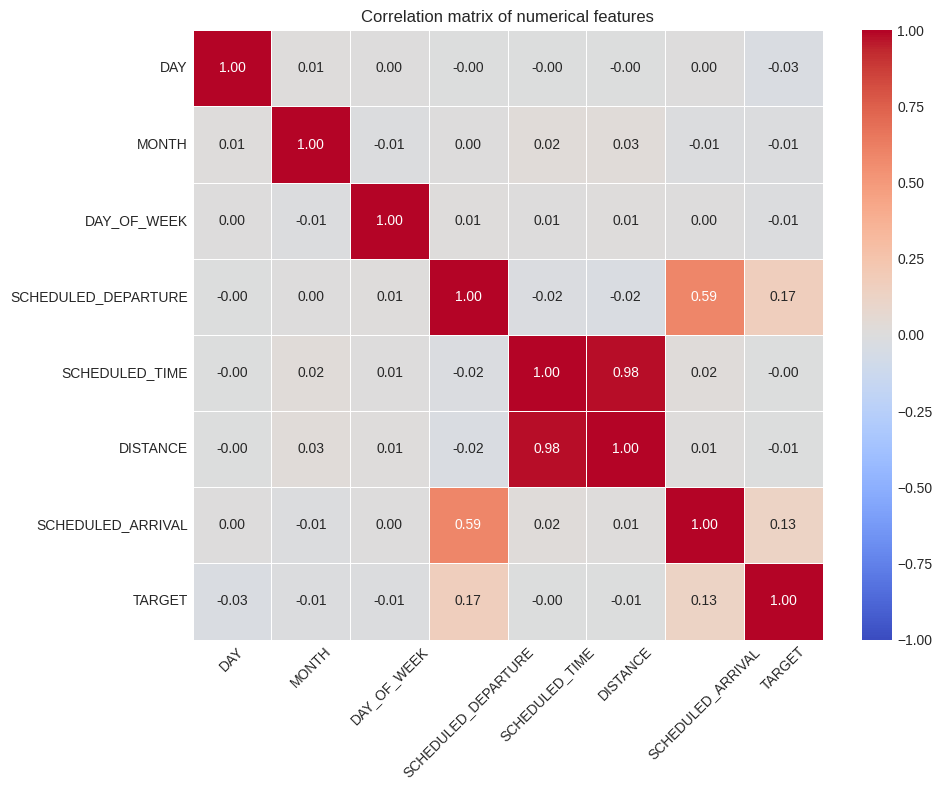

In [102]:
corr_cols = ['DAY',
             'MONTH',
             'DAY_OF_WEEK',
             'SCHEDULED_DEPARTURE',
             'SCHEDULED_TIME',
             'DISTANCE',
             'SCHEDULED_ARRIVAL',
             'TARGET']

corr_matrix = df_train[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, 
    vmax=1, 
    center=0,
    linewidths=0.5
)

plt.title('Correlation matrix of numerical features')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Дистанция и время в пути имеют очень высокую корреляцию, 0.98 - это почти 1. Это логично, ведь шаблонное время полёта всегда рассчитывается по дистанции, делённой на скорость. А скорость у пассажирских рейсов примерно одинаковая. Подбор необходимых признаков сделаем позже. Возможно, удаление некоторых улучшит модели.

# Feature Engineering
Добавим новые признаки, переведём время в `SIN` и `COS` соответственно, так как, например, 23:59 и 00:01 фактически находятся очень рядом, но для модели это неочевидно, если предварительно не перевести признак в "тригонометрический круг". С месяцем сделаем так же, иначе при появлении нового месяца через OHE в какой-нибудь валидационной части будут проблемы.

In [103]:
def feature_engineering(X: pd.DataFrame) -> pd.DataFrame:
    X_out = X.copy()
    sch_dep_hour = X['SCHEDULED_DEPARTURE'] // 100
    sch_dep_min = X['SCHEDULED_DEPARTURE'] % 100
    sch_dep_time_min = sch_dep_hour * 60 + sch_dep_min  
    
    X_out['SCH_DEP_SIN'] = np.sin(2 * np.pi * sch_dep_time_min / 1440)
    X_out['SCH_DEP_COS'] = np.cos(2 * np.pi * sch_dep_time_min / 1440)

    sch_arr_hour = X['SCHEDULED_ARRIVAL'] // 100
    sch_arr_min = X['SCHEDULED_ARRIVAL'] % 100
    sch_arr_time_min = sch_arr_hour * 60 + sch_arr_min

    X_out['SCH_ARR_SIN'] = np.sin(2 * np.pi * sch_arr_time_min / 1440)
    X_out['SCH_ARR_COS'] = np.cos(2 * np.pi * sch_arr_time_min / 1440)
    
    X_out['DEP_HOUR'] = sch_dep_hour
    X_out['ARR_HOUR'] = sch_arr_hour

    X_out['ORIGIN_AIRPORT_TRAFFIC'] = X_out.groupby(
        ['MONTH', 'DAY', 'ORIGIN_AIRPORT', 'DEP_HOUR']
    )['SCHEDULED_DEPARTURE'].transform('count')

    X_out['DEST_AIRPORT_TRAFFIC'] = X_out.groupby(
        ['MONTH', 'DAY', 'DESTINATION_AIRPORT', 'ARR_HOUR']
    )['SCHEDULED_ARRIVAL'].transform('count')

    X_out['MONTH_SIN'] = np.sin(2 * np.pi * (X_out['MONTH'] - 1) / 12)
    X_out['MONTH_COS'] = np.cos(2 * np.pi * (X_out['MONTH'] - 1) / 12)

    X_out = X_out.drop(columns=[
        'SCHEDULED_DEPARTURE', 'SCHEDULED_ARRIVAL', 'MONTH'
    ])

    return X_out

В дальнейшем есть смысл в кодировании `DAY_OF_WEEK`, `AIRLINE`, `TAIL_NUMBER` и аэропорты через One-Hot-Encoding.

# Baseline models training
Будем использовать следующие модели:
* Logistic Regression
* Linear SVM
* LightGBM
* CatBoost

In [104]:
df_train_fe = feature_engineering(df_train)
df_test_fe = feature_engineering(df_test)
display(df_train_fe.head())

,DAY,DAY_OF_WEEK,AIRLINE,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_TIME,DISTANCE,TARGET,SCH_DEP_SIN,SCH_DEP_COS,SCH_ARR_SIN,SCH_ARR_COS,DEP_HOUR,ARR_HOUR,ORIGIN_AIRPORT_TRAFFIC,DEST_AIRPORT_TRAFFIC,MONTH_SIN,MONTH_COS
0,1,4,US,N171US,SFO,CLT,286.0,2296,0,0.087156,0.996195,0.852640,-0.522499,0,8,4,7,0.0,1.0
1,1,4,DL,N3730B,SFO,MSP,217.0,1589,0,0.108867,0.994056,0.999962,-0.008727,0,6,4,3,0.0,1.0
2,1,4,NK,N635NK,LAS,MSP,181.0,1299,0,0.108867,0.994056,0.989016,0.147809,0,5,2,3,0.0,1.0
3,1,4,US,N584UW,LAX,CLT,273.0,2125,0,0.130526,0.991445,0.859406,-0.511293,0,8,2,7,0.0,1.0
4,1,4,AA,N3LAAA,SFO,DFW,195.0,1464,0,0.130526,0.991445,0.997859,0.065403,0,5,4,5,0.0,1.0


In [105]:
cat_base = ['DAY_OF_WEEK', 'AIRLINE', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT']

num_base = [
    'DAY', 'DISTANCE', 'SCHEDULED_TIME',
    'SCH_DEP_SIN', 'SCH_DEP_COS', 'SCH_ARR_SIN', 'SCH_ARR_COS',
    'DEP_HOUR', 'ARR_HOUR', 'ORIGIN_AIRPORT_TRAFFIC', 'DEST_AIRPORT_TRAFFIC', 'MONTH_SIN', 'MONTH_COS'
]

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=ConvergenceWarning)

## Ablation study
Исследуем влияние признаков на результаты моделей на тренировочных данных. Выберем 3 конфига с разными признаками, в дальнейшем будем работать с наиболее выигрышным.

In [106]:
X_train, y_train = df_train_fe.drop(columns=['TARGET']).copy(), df_train_fe['TARGET'].copy()
X_test, y_test = df_test_fe.drop(columns=['TARGET']).copy(), df_test_fe['TARGET'].copy()

CV_time_series = TimeSeriesSplit(n_splits=5)

experiments = {
    'Base config without TAIL_NUMBER': {
        'cat': cat_base,
        'num': num_base
    },
    'No multicollinearity config (no SCHEDULED_TIME)': {
        'cat': cat_base,
        'num': [n for n in num_base if n != 'SCHEDULED_TIME']
    },
    'All features config': {
        'cat': cat_base + ['TAIL_NUMBER'],
        'num': num_base
    }
}

for cfg, cols in experiments.items():
    name_list = []
    roc_auc_list = []
    pr_auc_list = []
    precision_list = []
    recall_list = []
    accuracy_list = []
    f1_list = []
    f2_list = []
    elapsed = []

    curr_features = cols['num'] + cols['cat']

    X_exp = X_train[curr_features].copy()

    preprocessor = ColumnTransformer([
        ('num', StandardScaler(), cols['num']),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cols['cat'])
    ])

    models = {
        'Logistic Regression': LogisticRegression(max_iter=1000, C=0.1, random_state=42),
        'SVM (linear)': LinearSVC(max_iter=2000, C=0.01, random_state=42),
        'Light GBM': LGBMClassifier(random_state=42, verbose=-1, n_jobs=-1),
        'CatBoost': CatBoostClassifier(random_seed=42, verbose=0, thread_count=-1)
    }

    for name, model in models.items():
        model_roc_auc_list = []
        model_pr_auc_list = []
        model_precision_list = []
        model_recall_list = []
        model_accuracy_list = []
        model_f1_list = []
        model_f2_list = []
        
        start = time.time()
        
        for t_idx, v_idx in CV_time_series.split(X_exp):
            X_t_idx, y_t_idx = X_exp.iloc[t_idx], y_train.iloc[t_idx]
            X_v_idx, y_v_idx = X_exp.iloc[v_idx], y_train.iloc[v_idx]

            pipeline = Pipeline([
                ('prep', preprocessor),
                ('model', model)
            ])

            pipeline.fit(X_t_idx, y_t_idx)
    
            if hasattr(pipeline, 'predict_proba'):
                scores = pipeline.predict_proba(X_v_idx)[:, 1]
                preds = (scores >= 0.5).astype(int)
            elif hasattr(pipeline, 'decision_function'):
                scores = pipeline.decision_function(X_v_idx)
                preds = (scores >= 0.0).astype(int)
            else:
                preds = pipeline.predict(X_v_idx)
                scores = preds

            model_roc_auc_list.append(roc_auc_score(y_v_idx, scores))
            model_pr_auc_list.append(average_precision_score(y_v_idx, scores))
            model_precision_list.append(precision_score(y_v_idx, preds, zero_division=0))
            model_recall_list.append(recall_score(y_v_idx, preds, zero_division=0))
            model_accuracy_list.append(accuracy_score(y_v_idx, preds))
            model_f1_list.append(f1_score(y_v_idx, preds, zero_division=0))
            model_f2_list.append(fbeta_score(y_v_idx, preds, beta=2, zero_division=0))

        end = time.time() - start

        name_list.append(name)
        roc_auc_list.append(round(np.mean(model_roc_auc_list), 4))
        pr_auc_list.append(round(np.mean(model_pr_auc_list), 4))
        precision_list.append(round(np.mean(model_precision_list), 4))
        recall_list.append(round(np.mean(model_recall_list), 4))
        accuracy_list.append(round(np.mean(model_accuracy_list), 4))
        f1_list.append(round(np.mean(model_f1_list), 4))
        f2_list.append(round(np.mean(model_f2_list), 4))
        elapsed.append(round(end, 2))
        
    benchmark_results = {
        'Model': name_list,
        'ROC-AUC': roc_auc_list,
        'PR-AUC': pr_auc_list,
        'Precision': precision_list,
        'Recall': recall_list,
        'Accuracy': accuracy_list,
        'F1-score': f1_list,
        'F2-score': f2_list,
        'Elapsed time': elapsed
    }

    display(HTML(f'<h3>{cfg}</h3>'))
    output = pd.DataFrame(benchmark_results)
    display(output.style.hide())

Model,ROC-AUC,PR-AUC,Precision,Recall,Accuracy,F1-score,F2-score,Elapsed time
Logistic Regression,0.654800,0.315700,0.374300,0.023800,0.790200,0.041700,0.028700,16.080000
SVM (linear),0.654200,0.315700,0.252200,0.004500,0.792100,0.008800,0.005600,22.800000
Light GBM,0.662000,0.317200,0.400600,0.050900,0.788600,0.089800,0.061500,14.730000
CatBoost,0.659500,0.320100,0.394500,0.105100,0.783100,0.162300,0.122300,209.410000


Model,ROC-AUC,PR-AUC,Precision,Recall,Accuracy,F1-score,F2-score,Elapsed time
Logistic Regression,0.654800,0.315700,0.369400,0.023800,0.790200,0.041800,0.028800,15.450000
SVM (linear),0.654300,0.315800,0.252800,0.004600,0.792100,0.009000,0.005700,20.960000
Light GBM,0.663000,0.318600,0.399700,0.050600,0.788700,0.089600,0.061300,14.080000
CatBoost,0.660300,0.319700,0.396500,0.102300,0.783900,0.159300,0.119300,210.400000


Model,ROC-AUC,PR-AUC,Precision,Recall,Accuracy,F1-score,F2-score,Elapsed time
Logistic Regression,0.653400,0.315200,0.406500,0.031800,0.789500,0.053800,0.038000,37.550000
SVM (linear),0.651900,0.314300,0.347000,0.009500,0.791700,0.017900,0.011700,67.160000
Light GBM,0.662500,0.318400,0.404800,0.047000,0.789300,0.083800,0.057000,21.410000
CatBoost,0.662300,0.320200,0.401000,0.082700,0.786900,0.134700,0.097800,281.140000


Наиболее высокое качество по ROC-AUC показали LightGBM и CatBoost. Удаление `SCHEDULED_TIME` практически не изменило качество моделей, что подтверждает его избыточность относительно `DISTANCE`. Добавление `TAIL_NUMBER` также не обеспечило устойчивого улучшения качества. По числовым показателям есть смысл в выборе конфига №2.

Полученные результаты показывают, что зависимость между характеристиками рейса и вероятностью задержки имеет также нелинейный характер и может эффективно моделироваться алгоритмами бустинга. При этом преимущество сложных моделей над Logistic Regression оказалось относительно небольшим, что говорит в целом о наличии достаточно сильной линейной составляющей в этих данных.

In [107]:
cat_features = cat_base
num_features = [n for n in num_base if n != 'SCHEDULED_TIME']

## Optuna hyperparameters selection
Возьмём наиболее сильные модели и подберём гиперпараметры через Optuna. Оптимизация будет с использованием временной кросс-валидации и целевой метрики PR-AUC, поскольку задача характеризуется дисбалансом классов.

In [108]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

curr_features = num_features + cat_features

X_tune = X_train[curr_features].copy()
y_tune = y_train.copy()

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cat_features)
])

In [109]:
def objective_lgbm(trial):
    params = {
        'objective': 'binary',
        'metric': 'prauc',
        'boosting_type': 'gbdt',
        'random_state': 42,
        'verbose': -1,
        'n_jobs': -1,
        'n_estimators': trial.suggest_int('n_estimators', 150, 400),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.15, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 20, 64),
        'max_depth': trial.suggest_int('max_depth', 4, 10),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 100),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True)
    }

    prauc_scores = []

    for t_idx, v_idx in CV_time_series.split(X_tune):
        X_t_idx, y_t_idx = X_tune.iloc[t_idx], y_tune.iloc[t_idx]
        X_v_idx, y_v_idx = X_tune.iloc[v_idx], y_tune.iloc[v_idx]

        pipeline = Pipeline([
            ('prep', preprocessor),
            ('model', LGBMClassifier(**params))
        ])

        pipeline.fit(X_t_idx, y_t_idx)
        probs = pipeline.predict_proba(X_v_idx)[:, 1]
        prauc_scores.append(average_precision_score(y_v_idx, probs))

    return np.mean(prauc_scores)

study_lgbm = optuna.create_study(direction='maximize')
study_lgbm.optimize(objective_lgbm, n_trials=25, show_progress_bar=True)

print(f'Best CV PR-AUC for LightGBM: {study_lgbm.best_value:.4f}')
print('Best parameters of LightGBM:', study_lgbm.best_params)

  0%|          | 0/25 [00:00<?, ?it/s]

Best CV PR-AUC for LightGBM: 0.3240
Best parameters of LightGBM: {'n_estimators': 177, 'learning_rate': 0.10910240092710825, 'num_leaves': 60, 'max_depth': 9, 'min_child_samples': 81, 'subsample': 0.8437245946956589, 'colsample_bytree': 0.779529174184401, 'reg_alpha': 4.561533260016832, 'reg_lambda': 0.047459765593509645}


In [110]:
def objective_cb(trial):
    params = {
        'eval_metric': 'PRAUC',
        'random_seed': 42,
        'verbose': 0,
        'thread_count': -1,
        'iterations': trial.suggest_int('iterations', 150, 350),
        'learning_rate': trial.suggest_float('learning_rate', 0.03, 0.15, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 10.0, log=True),
        'random_strength': trial.suggest_float('random_strength', 1e-2, 10.0, log=True)
    }

    prauc_scores = []

    for t_idx, v_idx in CV_time_series.split(X_tune):
        X_t_idx, y_t_idx = X_tune.iloc[t_idx], y_tune.iloc[t_idx]
        X_v_idx, y_v_idx = X_tune.iloc[v_idx], y_tune.iloc[v_idx]

        pipeline = Pipeline([
            ('prep', preprocessor),
            ('model', CatBoostClassifier(**params))
        ])

        pipeline.fit(X_t_idx, y_t_idx)
        probs = pipeline.predict_proba(X_v_idx)[:, 1]
        prauc_scores.append(average_precision_score(y_v_idx, probs))

    return np.mean(prauc_scores)

study_cb = optuna.create_study(direction='maximize')
study_cb.optimize(objective_cb, n_trials=25, show_progress_bar=True)

print(f'Best CV PR-AUC for CatBoost: {study_cb.best_value:.4f}')
print('Best parameters of CatBoost:', study_cb.best_params)

  0%|          | 0/25 [00:00<?, ?it/s]

Best CV PR-AUC for CatBoost: 0.3258
Best parameters of CatBoost: {'iterations': 316, 'learning_rate': 0.0800977284649364, 'depth': 6, 'l2_leaf_reg': 1.8332222269908713, 'random_strength': 4.309904797573014}


Наш эксперимент показывает, что обе модели способны эффективно решать поставленную задачу, но явного превосходства одной из них на этапе CV не наблюдается. Попробуем объединить эти модели.

# Stacking and blending model
Сделаем стекинг и блендинг из этих двух бустингов с подобранными гиперпараметрами.

In [111]:
oof_preds_lgbm = []
oof_preds_cb = []
oof_targets = []

for t_idx, v_idx in CV_time_series.split(X_tune):
    X_t_idx, y_t_idx = X_tune.iloc[t_idx], y_tune.iloc[t_idx]
    X_v_idx, y_v_idx = X_tune.iloc[v_idx], y_tune.iloc[v_idx]

    oof_targets.extend(y_v_idx)

    pipeline_lgbm = Pipeline([
        ('prep', preprocessor),
        ('model', LGBMClassifier(**study_lgbm.best_params, metric='prauc', objective='binary', random_state=42, verbose=-1, n_jobs=-1))
    ])
    pipeline_lgbm.fit(X_t_idx, y_t_idx)
    oof_preds_lgbm.extend(pipeline_lgbm.predict_proba(X_v_idx)[:, 1])

    pipeline_cb = Pipeline([
        ('prep', preprocessor),
        ('model', CatBoostClassifier(**study_cb.best_params, eval_metric='PRAUC', random_seed=42, verbose=0, thread_count=-1))
    ])
    pipeline_cb.fit(X_t_idx, y_t_idx)
    oof_preds_cb.extend(pipeline_cb.predict_proba(X_v_idx)[:, 1])

y_oof = np.array(oof_targets)

S_train = pd.DataFrame({
    'LightGBM': oof_preds_lgbm,
    'CatBoost': oof_preds_cb
})

blend_probs = 0.5 * S_train['LightGBM'] + 0.5 * S_train['CatBoost']

meta_model = LogisticRegression(C=1.0, random_state=42)
meta_model.fit(S_train, y_oof)
stack_probs = meta_model.predict_proba(S_train)[:, 1]

compare_dict = {
    'LightGBM (tuned)': S_train['LightGBM'],
    'CatBoost (tuned)': S_train['CatBoost'],
    'Blending (50/50)': blend_probs,
    'Stacking (meta-model is Logistic Regression)': stack_probs
}

summary = []

for model_name, probs in compare_dict.items():
    preds_half = (probs >= 0.5).astype(int)

    summary.append({
        'Approach': model_name,
        'ROC-AUC': round(roc_auc_score(y_oof, probs), 5),
        'PR-AUC': round(average_precision_score(y_oof, probs), 5),
        'Accuracy': round(accuracy_score(y_oof, preds_half), 4),
        'Precision': round(precision_score(y_oof, preds_half, zero_division=0), 4),
        'Recall': round(recall_score(y_oof, preds_half, zero_division=0), 4),
        'F1-score': round(f1_score(y_oof, preds_half, zero_division=0), 4),
        'F2-score': round(fbeta_score(y_oof, preds_half, beta=2, zero_division=0), 4)
    })

df_results = pd.DataFrame(summary).sort_values(by='PR-AUC', ascending=False).reset_index(drop=True)
display(df_results.style.hide())

Approach,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1-score,F2-score
Stacking (meta-model is Logistic Regression),0.666170,0.328630,0.791000,0.463700,0.042100,0.077300,0.051500
Blending (50/50),0.666160,0.328490,0.789900,0.455900,0.061000,0.107700,0.073800
CatBoost (tuned),0.664690,0.326780,0.789600,0.448900,0.059300,0.104700,0.071700
LightGBM (tuned),0.662530,0.323900,0.788200,0.436000,0.069100,0.119300,0.083100


Стекинг показал результаты лучше по сравнению с двумя бустингами по отдельности, попробуем теперь для этой модели подобрать оптимальный порог, чтобы лучше фиксировать задержку (увеличим recall).

# Optimal threshold selection
Будем рассматривать ошибки модели с точки зрения бизнеса:
* FP = 50 dollars
* FN = 250 dollars
 
Будем основываться на том, что при пропуске задержки нужно готовить резервный экипаж, будет срыв стыковок, порча продуктов и возможные дополнительные штрафы. Пока рассматриваем, что такая ошибка дороже, чем ложное предупреждение о задержке.


In [112]:
def model_error_cost(y_true, y_prob, th):
    y_pred = (y_prob >= th).astype(int)
    
    FP_cost = 50
    FN_cost = 250

    FP_errors = np.sum((y_true == False) & (y_pred == True))
    FN_errors = np.sum((y_true == True) & (y_pred == False))

    cost = (FP_errors * FP_cost) + (FN_errors * FN_cost)

    return cost

In [113]:
th_list = np.linspace(0.05, 0.8, 100)
cost_list = [model_error_cost(y_oof, stack_probs, th) for th in th_list]

min_cost_idx = np.argmin(cost_list)
best_th = th_list[min_cost_idx]
default_cost = model_error_cost(y_oof, stack_probs, 0.5)
save_sum = default_cost - cost_list[min_cost_idx]

cost_th_df = pd.DataFrame({
                'Best threshold': best_th,
                'Default threshold': '0.5',
                'Savings ($)': save_sum,
                'Cost reduction': save_sum/default_cost
}, index=[0])

display(cost_th_df.style.format({
    'Best threshold': '{:.4f}',
    'Savings ($)': '{:} $',
    'Cost reduction': '{:.2%}'
}).hide())

Best threshold,Default threshold,Savings ($),Cost reduction
0.1561,0.5,9660350 $,33.84%


Поскольку ошибка FN в рассматриваемой задаче существенно дороже ошибки FP, для практического применения модели был исследован выбор порога классификации с использованием заданной стоимости ошибок. На OOF-предсказаниях минимальная стоимость была достигнута, это позволило снизить расчётные финансовые потери по сравнению со стандартным порогом.

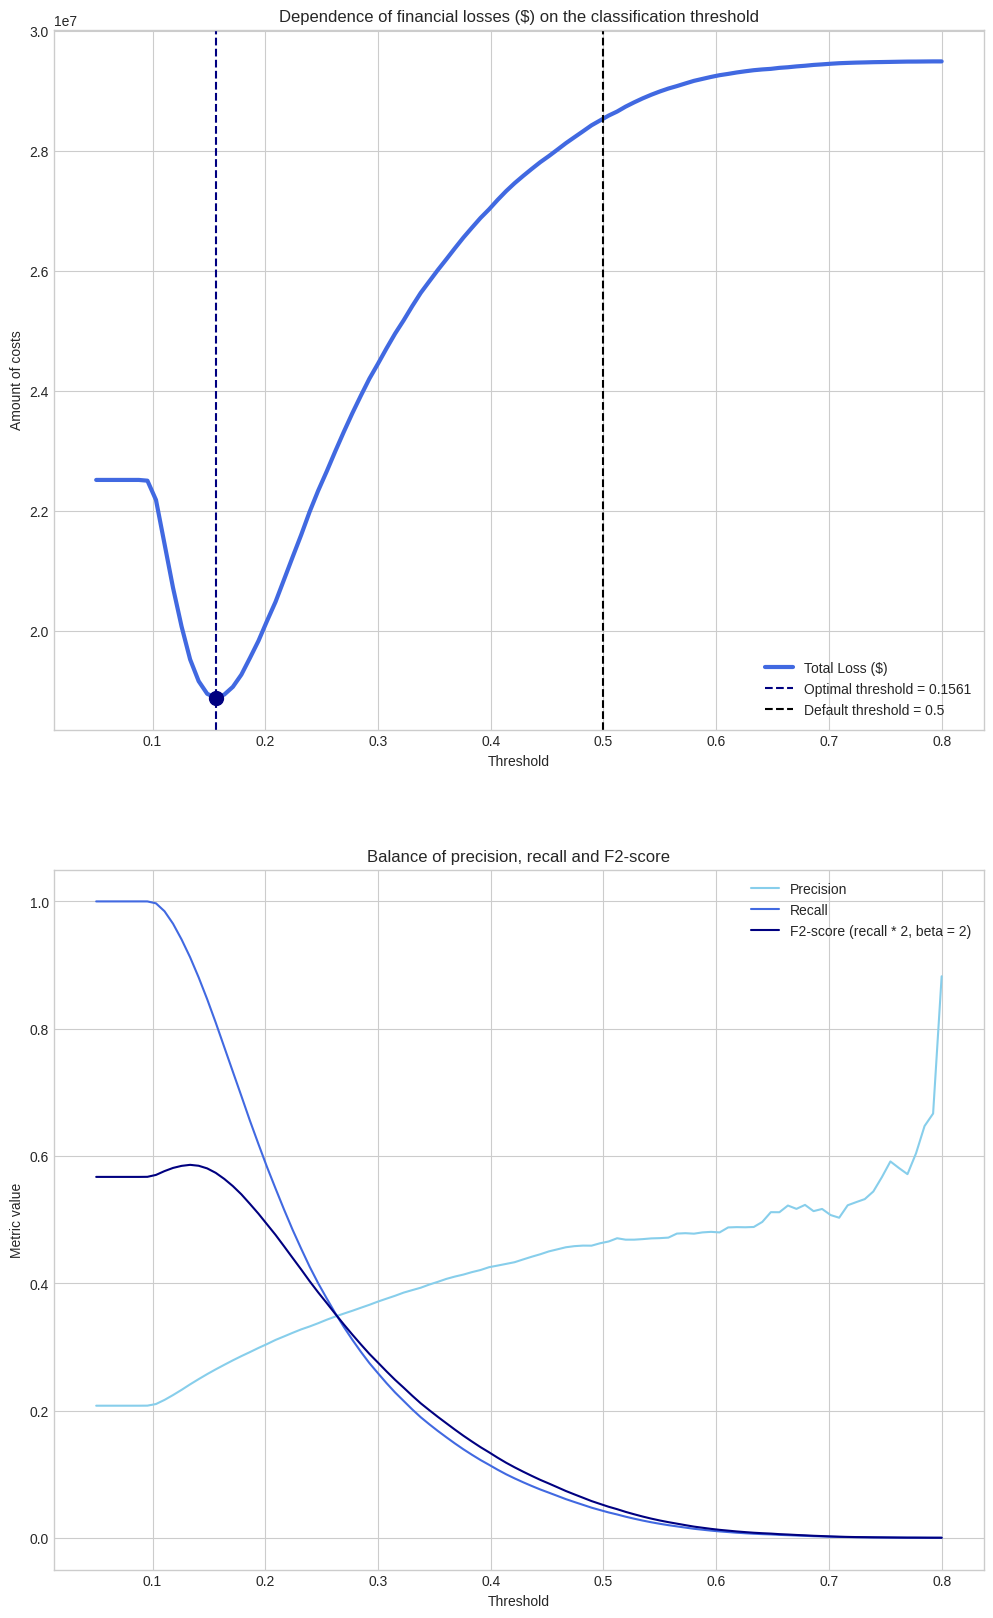

In [114]:
fig, ax = plt.subplots(2, 1, figsize=(12, 20))
ax[0].plot(th_list, cost_list, color='royalblue', lw=3, label='Total Loss ($)')
ax[0].axvline(best_th, color='navy', linestyle='--', label=f'Optimal threshold = {best_th:.4f}')
ax[0].axvline(0.5, color='black', linestyle='--', label=f'Default threshold = 0.5')
ax[0].scatter([best_th], [cost_list[min_cost_idx]], color='navy', s=100, zorder=5)
ax[0].set_title('Dependence of financial losses ($) on the classification threshold')
ax[0].set_xlabel('Threshold')
ax[0].set_ylabel('Amount of costs')
ax[0].legend()

precision_by_th = [precision_score(y_oof, (stack_probs >= th).astype(int), zero_division=0) for th in th_list]
recall_by_th = [recall_score(y_oof, (stack_probs >= th).astype(int), zero_division=0) for th in th_list]
f2_score_by_th = [fbeta_score(y_oof, (stack_probs >= th).astype(int), beta=2, zero_division=0) for th in th_list]

ax[1].plot(th_list, precision_by_th, label=f'Precision',color='skyblue')
ax[1].plot(th_list, recall_by_th, label='Recall', color='royalblue')
ax[1].plot(th_list, f2_score_by_th, label='F2-score (recall * 2, beta = 2)', color='navy')
ax[1].set_title('Balance of precision, recall and F2-score')
ax[1].set_xlabel('Threshold')
ax[1].set_ylabel('Metric value')
ax[1].legend()

plt.show()

# MLP
В качестве нейросетевого подхода была реализована MLP из трёх скрытых слоёв с использованием ReLU, LayerNorm и Dropout. Для борьбы с дисбалансом классов использовалась взвешенная бинарная кросс-энтропия (BCEWithLogitsLoss с pos_weight).


Постепенное уменьшение числа нейронов позволяет сначала сформировать более представительное скрытое представление исходных признаков, а затем последовательно сжимать его перед получением итогового решения. ReLU является простой и вычислительно эффективной нелинейной функцией. 

Для регуляризации применялся Dropout с вероятностями 0.3, 0.2 и 0.1 соответственно. Более сильная регуляризация использована на первых слоях, которые содержат больше параметров. Размеры же скрытых слоёв были выбраны вручную как компромисс между выразительностью модели и вычислительной сложностью.

In [115]:
X_train = X_train[curr_features]
X_test = X_test[curr_features]

train_mask = (df_train['MONTH'] <= 8).values
val_mask = (df_train['MONTH'] == 9).values

mlp_preprocessor = clone(preprocessor)

X_tr_dense = mlp_preprocessor.fit_transform(X_train.iloc[train_mask])
X_val_dense = mlp_preprocessor.transform(X_train.iloc[val_mask])

X_tr_tensor = torch.tensor(X_tr_dense.toarray(), dtype=torch.float32)
y_tr_tensor = torch.tensor(y_train[train_mask].values, dtype=torch.float32).unsqueeze(1)

X_val_tensor = torch.tensor(X_val_dense.toarray(), dtype=torch.float32)
y_val_tensor = torch.tensor(y_train[val_mask].values, dtype=torch.float32).unsqueeze(1)

train_loader = DataLoader(TensorDataset(X_tr_tensor, y_tr_tensor), batch_size=512, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_tensor, y_val_tensor), batch_size=1024, shuffle=False)

Изобразим несложную архитектуру сети по тексту выше:

In [116]:
class FlightDelayClsMLP(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.LayerNorm(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.LayerNorm(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 32),
            nn.LayerNorm(32),
            nn.ReLU(),
            nn.Dropout(0.1),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)

Проведем обучение и валидацию получившегося MLP с указанными характеристиками:

In [117]:
in_dim = X_tr_tensor.shape[1]
mlp = FlightDelayClsMLP(in_dim)

pos_weight = torch.tensor([(len(y_tr_tensor) - y_tr_tensor.sum()) / y_tr_tensor.sum()])
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(mlp.parameters(), lr=2e-4, weight_decay=1e-4)

epochs = 15
history = {
    'train_loss': [],
    'val_loss': [],
    'val_prauc': [],
    'val_rocauc': []
}

start_mlp_time = time.time()

for epoch in range(1, epochs + 1):
    mlp.train()
    total_train_loss = 0.0

    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        logits = mlp(batch_x)
        loss = criterion(logits, batch_y)
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item() * len(batch_x)

    train_loss = total_train_loss / len(train_loader.dataset)

    mlp.eval()
    total_val_loss = 0.0
    val_preds = []
    val_targets = []

    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            logits = mlp(batch_x)
            loss = criterion(logits, batch_y)
            total_val_loss += loss.item() * len(batch_x)
            probs = torch.sigmoid(logits).numpy().ravel()
            val_preds.extend(probs)
            val_targets.extend(batch_y.numpy().ravel())

    val_loss = total_val_loss / len(val_loader.dataset)
    val_prauc = average_precision_score(val_targets, val_preds)
    val_rocauc = roc_auc_score(val_targets, val_preds)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_prauc'].append(val_prauc)
    history['val_rocauc'].append(val_rocauc)

    print(f'Epoch {epoch:02d}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val PR-AUC: {val_prauc:.4f} | Val ROC-AUC: {val_rocauc:.4f}')

mlp_time = time.time() - start_mlp_time
print(f'MLP elapsed time: {mlp_time:.2f} sec.')

Epoch 01/15 | Train Loss: 1.0301 | Val Loss: 0.8843 | Val PR-AUC: 0.2091 | Val ROC-AUC: 0.6436
Epoch 02/15 | Train Loss: 1.0118 | Val Loss: 0.8880 | Val PR-AUC: 0.2088 | Val ROC-AUC: 0.6441
Epoch 03/15 | Train Loss: 1.0059 | Val Loss: 0.8731 | Val PR-AUC: 0.2103 | Val ROC-AUC: 0.6462
Epoch 04/15 | Train Loss: 1.0016 | Val Loss: 0.8700 | Val PR-AUC: 0.2078 | Val ROC-AUC: 0.6443
Epoch 05/15 | Train Loss: 0.9990 | Val Loss: 0.8668 | Val PR-AUC: 0.2091 | Val ROC-AUC: 0.6450
Epoch 06/15 | Train Loss: 0.9967 | Val Loss: 0.8670 | Val PR-AUC: 0.2079 | Val ROC-AUC: 0.6449
Epoch 07/15 | Train Loss: 0.9952 | Val Loss: 0.8656 | Val PR-AUC: 0.2064 | Val ROC-AUC: 0.6417
Epoch 08/15 | Train Loss: 0.9927 | Val Loss: 0.8673 | Val PR-AUC: 0.2062 | Val ROC-AUC: 0.6426
Epoch 09/15 | Train Loss: 0.9916 | Val Loss: 0.8646 | Val PR-AUC: 0.2073 | Val ROC-AUC: 0.6449
Epoch 10/15 | Train Loss: 0.9901 | Val Loss: 0.8691 | Val PR-AUC: 0.2064 | Val ROC-AUC: 0.6429
Epoch 11/15 | Train Loss: 0.9891 | Val Loss: 0.869

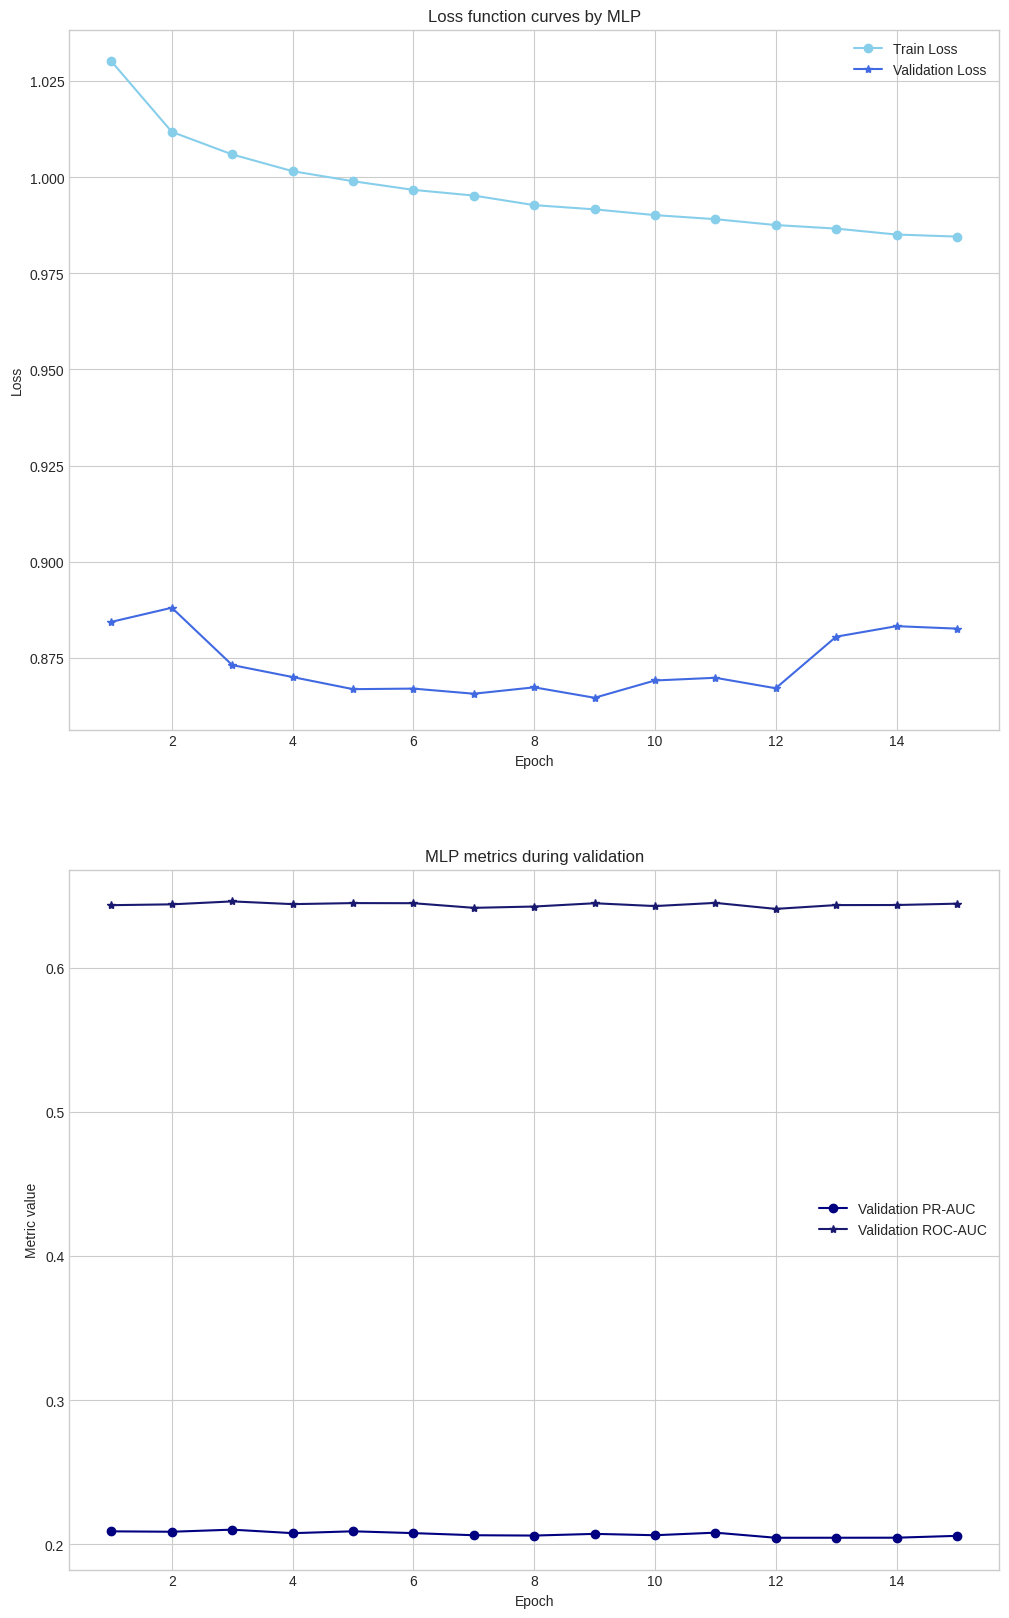

In [118]:
fig, ax = plt.subplots(2, 1, figsize=(12, 20))

ax[0].plot(range(1, epochs + 1), history['train_loss'], label='Train Loss', marker='o', color='skyblue')
ax[0].plot(range(1, epochs + 1), history['val_loss'], label='Validation Loss', marker='*', color='royalblue')
ax[0].set_title('Loss function curves by MLP')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].legend()

ax[1].plot(range(1, epochs + 1), history['val_prauc'], label='Validation PR-AUC', marker='o', color='navy')
ax[1].plot(range(1, epochs + 1), history['val_rocauc'], label='Validation ROC-AUC', marker='*', color='midnightblue')
ax[1].set_title('MLP metrics during validation')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Metric value')
ax[1].legend()

plt.show()

In [119]:
print(f'Proportion of positive class in train data: {y_train[train_mask].values.mean():.3f}')
print(f'Proportion of positive class in validation data: {y_train[val_mask].values.mean():.3f}')
print(f'Validation MLP PR-AUC: {max(history["val_prauc"]):.4f}')

Proportion of positive class in train data: 0.216
Proportion of positive class in validation data: 0.135
Validation MLP PR-AUC: 0.2103


Доля положительного класса в validation составила 13,5%, поэтому PR-AUC MLP заметно превышает соответствующий baseline. При этом после нескольких первых эпох дальнейшее обучение практически не улучшало качество, что показывает наличие быстрого выхода модели её максимум на этом наборе данных. На последних эпохах результат по лосс-функциям стал заметно хуже.

Полученный результат показывает, что для данного табличного набора данных бустинговые модели лучше используют структуру исходных признаков.

# Final test
Проведём итоговое тестирование всех моделей.

In [120]:
models_to_test = {
    'Logistic Regression' : Pipeline([
        ('prep', preprocessor), ('model', LogisticRegression(max_iter=1000, C=0.1, random_state=42))
    ]),
    'SVM (linear)': Pipeline([
        ('prep', preprocessor), ('model', LinearSVC(max_iter=2000, C=0.01, random_state=42))
    ]),
    'Light GBM (Tuned)': Pipeline([
        ('prep', preprocessor),
        ('model', LGBMClassifier(**study_lgbm.best_params, metric='prauc', 
                                 objective='binary', random_state=42, 
                                 verbose=-1, n_jobs=-1))
    ]),
    'CatBoost (Tuned)': Pipeline([
        ('prep', preprocessor),
        ('model', CatBoostClassifier(**study_cb.best_params, eval_metric='PRAUC', 
                                     random_seed=42, verbose=0, 
                                     thread_count=-1))
    ]),
}

test_probabilities = {}
training_times = {}

for name, pipe in models_to_test.items():
    start = time.time()
    pipe.fit(X_train, y_train)
    training_times[name] = round(time.time() - start, 2)

    if hasattr(pipe, 'predict_proba'):
        test_probabilities[name] = pipe.predict_proba(X_test)[:, 1]
    elif hasattr(pipe, 'decision_function'):
        decision = pipe.decision_function(X_test)
        test_probabilities[name] = 1 / (1 + np.exp(-decision))
    else:
        test_probabilities[name] = pipe.predict(X_test)

pr_lgbm = test_probabilities['Light GBM (Tuned)']
pr_cb = test_probabilities['CatBoost (Tuned)']
test_probabilities['Blending (50/50)'] = 0.5 * pr_lgbm + 0.5 * pr_cb
training_times['Blending (50/50)'] = 0.01

start = time.time()
S_test = pd.DataFrame({
    'LightGBM': pr_lgbm,
    'CatBoost': pr_cb
})
test_probabilities['Stacking (meta-model is Logistic Regression)'] = meta_model.predict_proba(S_test)[:, 1]
training_times['Stacking (meta-model is Logistic Regression)'] = round(time.time() - start, 2)

X_test_dense = mlp_preprocessor.transform(X_test)
X_test_tensor = torch.tensor(X_test_dense.toarray(), dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1)

mlp.eval()
with torch.no_grad():
    test_probabilities['MLP (3L)'] = torch.sigmoid(mlp(X_test_tensor)).numpy().flatten()
training_times['MLP (3L)'] = round(mlp_time, 2)

summary_table = []
y_test_array = np.array(y_test)

for name, probs in test_probabilities.items():
    preds_default = (probs >= 0.5).astype(int)
    cost_default = model_error_cost(y_test_array, probs, 0.5)

    preds_optimal = (probs >= best_th).astype(int)
    cost_optimal = model_error_cost(y_test_array, probs, best_th)

    saving_sum = cost_default - cost_optimal

    summary_table.append({
        'Model': name,
        'PR-AUC': round(average_precision_score(y_test_array, probs), 5),
        'ROC-AUC': round(roc_auc_score(y_test_array, probs), 5),
        'Recall (default threshold)': round(recall_score(y_test_array, preds_default, zero_division=0), 4),
        'Recall (optimal threshold)': round(recall_score(y_test_array, preds_optimal, zero_division=0), 4),
        'Precision (optimal threshold)': round(precision_score(y_test_array, preds_optimal, zero_division= 0), 4),
        'F1-score (optimal threshold)': round(f1_score(y_test_array, preds_optimal, zero_division=0), 4),
        'F2-score (optimal threshold)': round(fbeta_score(y_test_array, preds_optimal, zero_division=0, beta=2), 4),
        'Accuracy (optimal threshold)': round(accuracy_score(y_test_array, preds_optimal), 4),
        'Cost (default threshold) $': cost_default,
        'Cost (optimal threshold) $': cost_optimal,
        'Saved money $': saving_sum,
        'Cost reduction': saving_sum/cost_default,
        'Elapsed time (sec.)': training_times.get(name, 0.0)
    })

output = pd.DataFrame(summary_table).sort_values(by='Saved money $', ascending=False).reset_index(drop=True)

In [121]:
with pd.option_context('display.max_columns', None, 'display.max_colwidth', None):
    display(output.style.format({
        'PR-AUC': '{:.5f}',
        'ROC-AUC': '{:.5f}',
        'Recall (default threshold)': '{:.4f}',
        'Recall (optimal threshold)': '{:.4f}',
        'Precision (optimal threshold)': '{:.4f}',
        'F1-score (optimal threshold)': '{:.4f}',
        'F2-score (optimal threshold)': '{:.4f}',
        'Accuracy (optimal threshold)': '{:.4f}',
        'Elapsed time (sec.)': '{:.2f}',
        'Cost reduction': '{:.2%}'
    }).hide())

Model,PR-AUC,ROC-AUC,Recall (default threshold),Recall (optimal threshold),Precision (optimal threshold),F1-score (optimal threshold),F2-score (optimal threshold),Accuracy (optimal threshold),Cost (default threshold) $,Cost (optimal threshold) $,Saved money $,Cost reduction,Elapsed time (sec.)
Logistic Regression,0.26020,0.61718,0.0005,0.6564,0.2454,0.3573,0.4917,0.5427,7337550,5484000,1853550,25.26%,5.51
Light GBM (Tuned),0.26080,0.61965,0.0050,0.5941,0.2506,0.3525,0.4663,0.5774,7319450,5586300,1733150,23.68%,6.91
Blending (50/50),0.25031,0.60956,0.0032,0.5857,0.2445,0.3450,0.4579,0.5693,7328400,5697400,1631000,22.26%,0.01
Stacking (meta-model is Logistic Regression),0.24504,0.60408,0.0017,0.6009,0.2412,0.3442,0.4628,0.5567,7334250,5703600,1630650,22.23%,0.01
CatBoost (Tuned),0.23821,0.59610,0.0049,0.5619,0.2384,0.3347,0.4419,0.5675,7324500,5850400,1474100,20.13%,54.96
SVM (linear),0.26058,0.61630,0.0000,1.0000,0.1937,0.3245,0.5456,0.1937,7339000,6111600,1227400,16.72%,6.95
MLP (3L),0.20913,0.53990,0.3144,0.9920,0.1961,0.3274,0.5475,0.2108,6850700,6028800,821900,12.00%,203.78


На временной тестовой выборке результаты оказались ниже, чем на кросс-валидации, что указывает на наличие временного сдвига между обучающим и будущим периодами. Наиболее высокий PR-AUC показал LGBM, практически на уровне SVM и Logistic Regression. При этом LightGBM получил максимальный ROC-AUC.

Таким образом, выбор лучшей модели зависит от используемой метрики: по PR-AUC лучшими оказались линейные модели (LGBM вышел буквально на несколько процентов), тогда как LightGBM лучше ранжирует наблюдения по вероятности задержки согласно ROC-AUC. В то же время, ранжируя по количеству сохранённых денежных средств, можно сделать вывод, что на данный момент на текущем наборе тестовой выборки действительно выигрывает логистическая регрессия.

Наиболее сложные модели не продемонстрировали гарантированного преимущества на будущем временном периоде. В частности, stacking и blending, несмотря на небольшое преимущество на OOF-данных.

# Conclusion

В рамках проекта была построена система бинарной классификации для прогнозирования задержки вылета на 15 и более минут. В процессе работы были выполнены анализ данных, удаление признаков, недоступных до вылета, feature engineering временных характеристик, обработка дисбаланса классов, временная CV и подбор гиперпараметров через Optuna.

На этапе CV наиболее перспективными моделями оказались LightGBM и CatBoost, однако на временной тестовой выборке их преимущество над линейными моделями не сохранилось. Наибольший PR-AUC показал LGBM, немного меньше - Logistic Regression и SVM, также LGBM получила лучший ROC-AUC.

Проведённые эксперименты также показали, что SCHEDULED_TIME оказался избыточным относительно DISTANCE, а TAIL_NUMBER не дал устойчивого улучшения качества. Stacking и blending также не обеспечили прироста на именно тестовой выборке.

Для данной задачи особенно важны выбор корректного временного разбиения и рабочего порога классификации. При учёте различной стоимости **FP** и **FN** снижение порога значительно повышает **recall** и позволяет уменьшить ожидаемые финансовые потери.